In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys

if(os.path.exists('/content/sample_data')):
  sys.path.append('differentiable-trees/')


sys.path.append('../')
import jax.numpy as jnp
import jax.nn as nn

import jax
import optax
import wandb
import argparse
import functools

import pydot
import numpy as np
from modules.vis_utils import *
from modules.tree_func import *
from modules.gt_tree_gen import *

from matplotlib import rc
import plotly.express as px
rc('animation', html='jshtml')

In [2]:
args = {}

args['groundtruth'] = True
args['fix_seqs'] = True
args['fix_tree'] = False
args['initialize_tree'] = False
args['initialize_seq'] = True

#### Define Sequence length and number of leaves
seq_length  = 10

n_leaves    = 4
n_ancestors = n_leaves - 1
n_all       = n_leaves + n_ancestors
n_mutations = 2
n_letters   = 21

args['tree_loss_schedule'] = [0,0.02,1,50]
 
metadata = {
    'n_all' : n_all,
    'n_leaves' : n_leaves, 
    'n_ancestors' : n_ancestors,
    'seq_length' : seq_length,
    'n_letters' : n_letters,
    'n_mutations' : n_mutations,
    'args': args,
    'exp_name' : f"_test" ,
    'seed' : 42,
    'seq_temp': 0.5,
    'lr': 0.1,
    'epochs': 100,
    'tLs': args['tree_loss_schedule'] # #tree loss schedule
    }
print(metadata)

wandb.init(project="test", name = metadata['exp_name'], entity="ramithx1", config = metadata, tags=["FASRC","Fixed Groundtruth", "Fixed GT Seqs Order", "feature-tests"])
metadata['exp_name'] = None

Failed to detect the name of this notebook, you can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.


{'n_all': 7, 'n_leaves': 4, 'n_ancestors': 3, 'seq_length': 10, 'n_letters': 21, 'n_mutations': 2, 'args': {'groundtruth': True, 'fix_seqs': True, 'fix_tree': False, 'initialize_tree': False, 'initialize_seq': True, 'tree_loss_schedule': [0, 0.02, 1, 50]}, 'exp_name': '_test', 'seed': 42, 'seq_temp': 0.5, 'lr': 0.1, 'epochs': 100, 'tLs': [0, 0.02, 1, 50]}


wandb: Currently logged in as: fypteam-e77eba03 (use `wandb login --relogin` to force relogin)


In [3]:
key = jax.random.PRNGKey(metadata['seed'])
#### Generate a random sequence of 0s and 1s

seqs = jax.random.randint(key, shape = (n_all, seq_length, n_letters), minval = 0, maxval = 2).astype(jnp.bfloat16)

#### Generate a base tree
base_tree = jnp.zeros((n_all, n_all))

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [4]:
if(True):
    seqs, gt_seqs, tree = generate_groundtruth(metadata, metadata['seed'])

    seqs    = jax.nn.one_hot(seqs, n_letters).astype(jnp.bfloat16)
    gt_seqs = jax.nn.one_hot(gt_seqs, n_letters).astype(jnp.bfloat16)

    #if we don't want sequences to change, set seqs to gt_seqs
    if(True):
        seqs = gt_seqs

    gt_tree = show_graph_with_labels(tree, n_leaves, True)
    gt_seqs_plot = px.imshow(jnp.argmax(gt_seqs, axis = 2), text_auto=True)

    gt_cost           = compute_cost(gt_seqs, tree, metadata, surrogate_loss = False)
    gt_cost_surrogate = compute_cost(gt_seqs, tree, metadata)
    
    gt_tree_force_loss, gt_loop_loss, gt_bidirection_loss = enforce_graph(tree, 10, metadata)

    wandb.log({
        "Groundtruth Tree" : wandb.Image(gt_tree),
        "Groundtruth Seq" : wandb.data_types.Plotly(gt_seqs_plot),

        "Groundtruth Tree Force Loss" : gt_tree_force_loss,
        "Groundtruth Loop Loss" : gt_loop_loss,
        "Groundtruth Bidirection Loss" : gt_bidirection_loss,
        "Groundtruth Traversal Cost (surrogate)" : gt_cost_surrogate,
        "Groundtruth Traversal Cost" : gt_cost,
        "Groundtruth Total Loss" : gt_tree_force_loss + gt_loop_loss + gt_bidirection_loss + gt_cost
        })

TypeError: Object of type Array is not JSON serializable

In [5]:

#### Define optimizer and parameters (t and the ancestor sequences)
optimizer = optax.adam(metadata['lr'])
params = {
    't': jax.random.normal(key, (n_all - 1,n_ancestors))
    }


## Manually override the parameters such that the updated tree is the same as the base tree
if(args['initialize_tree']):
    params['t'] = tree[0:-1,n_leaves:]

#### Add the ancestor sequences to the parameters
for i in range(0, n_ancestors):
    params[str(i)] = jax.random.normal(key+i, (seq_length, n_letters)).astype(jnp.bfloat16)

#### Initialize the optimizer
opt_state = optimizer.init(params)


print("parameters to optimize:", end = " -> ")
print(params.keys())

fig2 = show_graph_with_labels(discretize_tree_topology(update_tree(params, base_tree), n_all),n_leaves, True)



parameters to optimize: -> dict_keys(['t', '0', '1', '2'])


In [6]:
compute_loss(params, seqs, base_tree, metadata, metadata['tLs'][0], verbose=True)

came to ->  6  with path prob  1
going to visit ->  [4 6]  with probs :  [0.62681043 1.        ]  conflicts :  0
came to ->  4  with path prob  0.62681043
going to visit ->  [3 1]  with probs :  [0.19876231 0.24856289]  conflicts :  0
came to ->  3  with path prob  0.19876231
going to visit ->  [5 6]  with probs :  [0. 0.]  conflicts :  0
came to ->  5  with path prob  0.0
going to visit ->  [5 2]  with probs :  [0. 0.]  conflicts :  0
came to ->  5  with path prob  0.0
going to visit ->  [5 2]  with probs :  [0. 0.]  conflicts :  0
came to ->  2  with path prob  0.0
going to visit ->  [5 6]  with probs :  [0. 0.]  conflicts :  0.0
## came back to ->  2  conflicts :  0.0
## came back to ->  5  conflicts :  0.0
## came back to ->  5  conflicts :  0.0
## came back to ->  3  conflicts :  0.0
came to ->  1  with path prob  0.24856289
going to visit ->  [5 6]  with probs :  [0. 0.]  conflicts :  0.0
## came back to ->  1  conflicts :  0.0
## came back to ->  4  conflicts :  0.0
## came back

(Array(23., dtype=float32),
 Array(15.105635, dtype=float32),
 Array(53.7302, dtype=float32),
 Array(58.374626, dtype=float32),
 Array(123.671165, dtype=float32),
 Array(5.925864, dtype=float32),
 Array(15.105635, dtype=float32))

In [16]:
t_t = jnp.array([
       [0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0]])

In [17]:
compute_cost_recursive(t_t,True)

came to ->  6  with path prob  1
going to visit ->  [6 4]  with probs :  [0 1]  conflicts :  0
came to ->  4  with path prob  1
going to visit ->  [0 1]  with probs :  [1 1]  conflicts :  0
came to ->  0  with path prob  1
going to visit ->  [5 6]  with probs :  [0 0]  conflicts :  0
came to ->  5  with path prob  0
going to visit ->  [2 3]  with probs :  [0 0]  conflicts :  0
came to ->  2  with path prob  0
going to visit ->  [5 6]  with probs :  [0 0]  conflicts :  0
came to ->  5  with path prob  0
going to visit ->  [2 3]  with probs :  [0 0]  conflicts :  0
came to ->  3  with path prob  0
going to visit ->  [5 6]  with probs :  [0 0]  conflicts :  0.0
came to ->  5  with path prob  0
going to visit ->  [2 3]  with probs :  [0 0]  conflicts :  0.0
## came back to ->  5  conflicts :  0.0
## came back to ->  3  conflicts :  0.0
## came back to ->  5  conflicts :  0.0
## came back to ->  2  conflicts :  0.0
## came back to ->  5  conflicts :  0.0
## came back to ->  0  conflicts :  

Array(3., dtype=float32, weak_type=True)

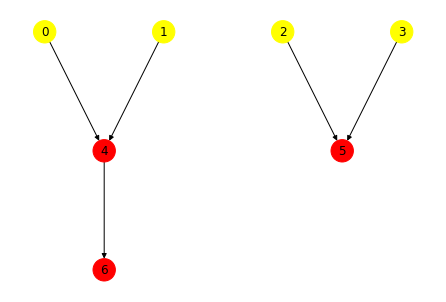

In [18]:
show_graph_with_labels(t_t,4, True)

In [76]:
t_tt = jax.nn.softmax(t_t, axis = 1)

In [74]:
t_tt

Array([[4.5387562e-05, 4.5387562e-05, 4.5387562e-05, 4.5387562e-05,
        9.9972755e-01, 4.5387562e-05, 4.5387562e-05],
       [4.5387562e-05, 4.5387562e-05, 4.5387562e-05, 4.5387562e-05,
        9.9972755e-01, 4.5387562e-05, 4.5387562e-05],
       [4.5387569e-05, 4.5387569e-05, 4.5387569e-05, 4.5387569e-05,
        4.5387569e-05, 9.9972767e-01, 4.5387569e-05],
       [4.5387569e-05, 4.5387569e-05, 4.5387569e-05, 4.5387569e-05,
        4.5387569e-05, 9.9972767e-01, 4.5387569e-05],
       [4.5387562e-05, 4.5387562e-05, 4.5387562e-05, 4.5387562e-05,
        4.5387562e-05, 4.5387562e-05, 9.9972755e-01],
       [4.5387562e-05, 4.5387562e-05, 4.5387562e-05, 4.5387562e-05,
        4.5387562e-05, 4.5387562e-05, 9.9972755e-01],
       [1.4285715e-01, 1.4285715e-01, 1.4285715e-01, 1.4285715e-01,
        1.4285715e-01, 1.4285715e-01, 1.4285715e-01]], dtype=float32)

In [13]:
t_t

Array([[0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 0]], dtype=bfloat16)

In [10]:
t_t = tree.at[-1,-1].set(0)

In [12]:
_ = 0

if(args['fix_tree']): 
    t_ = base_tree
else:
    t_ = update_tree(params, base_tree)
t_d           = discretize_tree_topology(t_,n_all)
tree_at_epoch        = show_graph_with_labels(t_d, n_leaves, True)
tree_matrix_at_epoch = px.imshow(t_, text_auto=True)

###~ Get the current sequences as a plot
if(args['fix_seqs']):
    seqs_ = seqs
else:
    seqs_ = update_seq(params, seqs, metadata['seq_temp'])
new_seq = px.imshow(jnp.argmax(seqs_, axis = 2), text_auto=True)

## Compute the loss and the metrics for loggings purposes
##=> sort of forward model (using params to generate new sequences and tree)
#=> Compute the gradients

In [14]:
grads = jax.grad(compute_loss)(params, seqs, base_tree, metadata, metadata['tLs'][0])
cost, cost_surrogate, tree_force_loss, loop_loss, bidirection_loss, loss = compute_loss(params, seqs, base_tree, metadata, metadata['tLs'][0], verbose = True)


In [ ]:
## Log the metrics
if(_%20==0):
    wandb.log(
        {"epoch":_, 

        "loss":loss,
        "traversal cost": cost,
        "traversal cost (surrogate)": cost_surrogate,
        "tree force loss": tree_force_loss,
        "loop loss": loop_loss,
        "bidirection loss": bidirection_loss,

        "tree":wandb.Image(tree_at_epoch),
        "tree matrix":wandb.data_types.Plotly(tree_matrix_at_epoch),
        "Seq":wandb.data_types.Plotly(new_seq),
        "tLs":metadata['tLs'][0],})

if(_%100==0):
    print("{:.5f}".format(loss,end = " \n"))

#=> Update the parameters
updates, opt_state = optimizer.update(grads, opt_state)
params = optax.apply_updates(params, updates)

### update the tree loss schedule
if(_%metadata['tLs'][3]==0):
    metadata['tLs'][0] = min(metadata['tLs'][2], metadata['tLs'][0] + metadata['tLs'][1])